# Chương 6. Deep Graph: GCN trên đồ thị cổ phiếu VN30

**Môn:** Phát triển Hệ thống Thông minh · **Sinh viên:** Nguyễn Thành Trung (B23DCCN861) · **Lớp:** D23CTPM01-B · **Nhóm lớp CT, nhóm 07**

Notebook này chạy lại từng bước thí nghiệm của Chương 6 trong tiểu luận và giải thích kỹ từng đoạn mã. Mã đầy đủ nằm ở `scripts/tieuluan/complete_gnn.py`;
demo web của chương chạy bằng `python deepgraph_demo/server.py --open` (cổng 8300) hoặc là tab Chương 6 của demo gộp `python tieuluan_demo/server.py --open` (cổng 8500).

## Ý tưởng

Dữ liệu dạng bảng coi mỗi dòng là độc lập. Nhưng cổ phiếu thì liên quan nhau: cùng ngành, cùng chịu một cú sốc thị trường. **Mạng nơ-ron đồ thị (GNN)** cho phép mỗi
nút (một cổ phiếu) cập nhật biểu diễn của mình bằng cách trộn thông tin của các nút lân cận. Notebook trả lời hai câu hỏi và nói thẳng kết quả:

| Bài toán | Câu hỏi | Nơi trong notebook |
|---|---|---|
| A. Dự báo | Đồ thị có giúp đoán cổ phiếu nào có lợi suất 5 phiên tới cao hơn trung vị rổ không? | Phần 1–5 |
| B. Phân loại nút | Biết ngành của 1/3 số mã, đồ thị có giúp đoán ngành của phần còn lại không? | Phần 6 |
| C. Giới hạn | Chồng nhiều lớp GCN thì điều gì xảy ra (over-smoothing)? | Phần 7 |

## Cách chạy và cách đọc

1. Chọn **Kernel → Restart Kernel and Run All** (khoảng 1–2 phút). Dữ liệu giá nằm sẵn ở `data/tieuluan/raw/vn_stocks/`.
2. Mỗi phần có thứ tự: **ô Markdown giải thích → ô mã → kết quả**. Đọc phần giải thích trước.
3. Các ô "chạy thu nhỏ" (1–2 seed, ít epoch) chỉ để thấy vòng học chạy thật; **bảng chính thức** (5 seed, 80 epoch) đọc từ `data/tieuluan/gnn/results.json`.

> **Lưu ý:** đây là thí nghiệm học tập trên 27 mã. Không có kết luận về lợi nhuận giao dịch.

## 0. Thiết lập

Tìm thư mục gốc của dự án (đi ngược lên các thư mục cha đến khi gặp `scripts/tieuluan`) để `import` hoạt động dù notebook mở từ đâu. `show_source` in mã
nguồn của một hàm/lớp bằng `inspect.getsource`, nhờ đó ta đọc đúng đoạn mã đang chạy thay vì chép tay.

In [1]:
import os, sys, json, inspect, time
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/tieuluan/complete_gnn.py").exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
from scripts.tieuluan import complete_gnn as G
torch.set_num_threads(2)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

def show_source(obj):
    print(inspect.getsource(obj))

print("Thư mục gốc:", ROOT)
print("Phiên bản torch:", torch.__version__)

Thư mục gốc: E:\WINDOW\Project\intelligent-system-assignment-01
Phiên bản torch: 2.13.0+cpu


## 1. Dữ liệu: bảng giá 27 cổ phiếu

**Bài toán A.** Mỗi ngày giao dịch, mỗi cổ phiếu là một **nút**. Nhãn của nút là 1 nếu lợi suất 5 phiên tới của cổ phiếu cao hơn **trung vị của cả rổ** trong ngày đó, ngược lại là 0.
Dùng trung vị của rổ làm mốc nên nhãn luôn cân bằng (khoảng 50/50) và xu hướng chung của thị trường bị loại bỏ: mô hình phải so sánh các mã với nhau, không thể "đoán thị trường tăng".

**Hàm `load_panel`:**
- Duyệt dict `SECTORS` (27 mã, gán ngành thủ công theo hoạt động chính), đọc từng tệp CSV, bỏ ngày trùng và sắp theo ngày.
- Cắt từ ngày mà **mọi** mã đều đã có dữ liệu (`start = max(first_valid_index)`), lấp tối đa 3 ngày thiếu bằng `ffill(limit=3)`, rồi bỏ ngày còn thiếu. Nhờ vậy ma trận giá không có ô trống.

In [2]:
show_source(G.load_panel)
close, vol = G.load_panel()
tickers = list(close.columns)
print("Kích thước bảng giá (ngày x mã):", close.shape)
print("Từ", close.index[0].date(), "đến", close.index[-1].date())
print("27 mã theo ngành:")
for sec, ts in G.SECTORS.items():
    print(f"  {sec:<22} {len(ts):>2} mã: {', '.join(ts)}")
display(close.tail(3).round(2))

def load_panel():
    """Giá đóng cửa và khối lượng của các mã có dữ liệu liên tục từ 2018-06."""
    close, vol = {}, {}
    for sec, ts in SECTORS.items():
        for t in ts:
            d = pd.read_csv(os.path.join(RAW, t + ".csv"), parse_dates=["date"]).drop_duplicates("date").set_index("date").sort_index()
            close[t], vol[t] = d["close"], d["volume"]
    close, vol = pd.DataFrame(close), pd.DataFrame(vol)
    start = max(c.first_valid_index() for _, c in close.items())
    close, vol = close.loc[start:].ffill(limit=3), vol.loc[start:].fillna(0)
    close = close.dropna(axis=0, how="any")
    return close, vol.loc[close.index]



Kích thước bảng giá (ngày x mã): (1627, 27)
Từ 2020-02-26 đến 2026-09-30
27 mã theo ngành:
  Ngân hàng              12 mã: ACB, BID, CTG, HDB, LPB, MBB, SHB, STB, TCB, VCB, VIB, VPB
  Bất động sản            3 mã: VHM, VIC, VRE
  Tiêu dùng               5 mã: MCH, MSN, MWG, SAB, VNM
  Dầu khí - năng lượng    2 mã: BSR, GAS
  Chứng khoán             1 mã: SSI
  Công nghệ               1 mã: FPT
  Vật liệu                2 mã: HPG, GVR
  Hàng không              1 mã: VJC


,ACB,BID,CTG,HDB,LPB,MBB,SHB,STB,TCB,VCB,...,MWG,SAB,VNM,BSR,GAS,SSI,FPT,HPG,GVR,VJC
date,,,,,,,,,,,,,,,,,,,,,
2026-09-28,21.10,35.75,29.85,27.5,45.5,19.80,11.50,77.2,32.85,58.3,...,72.0,43.35,60.3,32.4,83.5,20.15,63.7,20.20,32.2,132.9
2026-09-29,21.05,35.90,29.75,27.4,43.5,19.60,11.45,75.8,32.60,58.0,...,71.9,43.05,60.3,32.5,84.9,20.15,63.2,20.30,33.3,133.5
2026-09-30,21.10,35.95,30.00,27.5,44.0,19.65,11.45,74.0,32.55,58.0,...,72.4,42.90,59.4,31.4,82.0,20.10,63.0,20.15,33.3,132.0


## 2. Đặc trưng và nhãn

**Hàm `build_features`** tạo 8 đặc trưng cho mỗi (ngày, mã):
- 6 đặc trưng **lợi suất quá khứ** theo các độ trễ `LAGS = (1, 2, 3, 5, 10, 20)`. Mỗi cái **trừ trung bình thị trường** cùng ngày (`r.sub(r.mean(axis=1), axis=0)`), nên chỉ còn phần chênh lệch giữa các mã.
- 1 đặc trưng **độ biến động 20 phiên** (độ lệch chuẩn của lợi suất ngày).
- 1 đặc trưng **khối lượng bất thường**: khối lượng hôm nay so với trung bình 20 phiên, chia độ lệch chuẩn.

Tensor đầu vào có dạng `(ngày, nút, đặc trưng)`. Nhãn `y` dùng `shift(-HORIZON)`: lợi suất **tương lai** chỉ dùng để dán nhãn, không bao giờ làm đặc trưng.
Ngày nào còn NaN (đầu chuỗi do cửa sổ 20 phiên, cuối chuỗi do chưa đủ 5 phiên tới) bị loại ở dòng `ok`.

In [3]:
show_source(G.build_features)
X, y, fwd, dates = G.build_features(close, vol)
print("X (ngày, nút, đặc trưng):", X.shape, "| y:", y.shape)
print("Tỉ lệ nhãn 1 (cao hơn trung vị rổ):", round(float(y.mean()), 4))
print("Ngày đầu / cuối còn dùng được:", dates[0].date(), dates[-1].date())

def build_features(close, vol):
    ret = np.log(close).diff()
    feats = []
    for k in LAGS:
        r = np.log(close).diff(k)
        feats.append(r.sub(r.mean(axis=1), axis=0))  # trừ trung bình thị trường: chỉ giữ phần chênh lệch giữa các mã
    feats.append(ret.rolling(20).std())
    feats.append((vol - vol.rolling(20).mean()) / (vol.rolling(20).std() + 1e-9))
    X = np.stack([f.values for f in feats], axis=-1)  # (ngày, nút, đặc trưng)
    fwd = np.log(close).shift(-HORIZON) - np.log(close)
    y = (fwd.sub(fwd.median(axis=1), axis=0) > 0).astype(float).values
    ok = ~np.isnan(X).any(axis=(1, 2)) & ~fwd.isna().any(axis=1).values
    dates = close.index
    return X[ok], y[ok], fwd.values[ok], dates[ok]

X (ngày, nút, đặc trưng): (1602, 27, 8) | y: (1602, 27)
Tỉ lệ nhãn 1 (cao hơn trung vị rổ): 0.4809
Ngày đầu / cuối còn dùng được: 2020-03-30 2026-09-23


## 3. Chia train/val/test theo thời gian và chuẩn hóa

Dữ liệu chuỗi thời gian **không được xáo trộn ngẫu nhiên**, nếu không tương lai lọt vào tập huấn luyện. Ta cắt theo ngày:
**train đến 31/12/2022 · validation năm 2023 · test từ 2024 trở đi.**

Hai chi tiết chống rò rỉ:
1. `[:-HORIZON]` bỏ 5 ngày cuối của train và val: nhãn của những ngày này dùng giá nằm trong giai đoạn kế tiếp.
2. Trung bình `mu` và độ lệch chuẩn `sd` để chuẩn hóa chỉ tính **trên tập train**, rồi áp cho cả val và test.

In [4]:
tr = dates <= pd.Timestamp(G.SPLIT["train_end"])
va = (dates > pd.Timestamp(G.SPLIT["train_end"])) & (dates <= pd.Timestamp(G.SPLIT["val_end"]))
te = dates > pd.Timestamp(G.SPLIT["val_end"])
idx = np.arange(len(dates))
tr_i, va_i, te_i = idx[tr][:-G.HORIZON], idx[va][:-G.HORIZON], idx[te]
mu = X[tr_i].reshape(-1, X.shape[-1]).mean(0)
sd = X[tr_i].reshape(-1, X.shape[-1]).std(0) + 1e-9
Xn = ((X - mu) / sd).astype(np.float32)
print(f"train {len(tr_i)} ngày | val {len(va_i)} ngày | test {len(te_i)} ngày")
print("Tỉ lệ nhãn 1 trong test:", round(float(y[te_i].mean()), 4), "(mức đoán mò ≈ 0,5 cho AUC)")

train 679 ngày | val 244 ngày | test 669 ngày
Tỉ lệ nhãn 1 trong test: 0.4807 (mức đoán mò ≈ 0,5 cho AUC)


## 4. Xây đồ thị: ba cách nối các cổ phiếu

Đồ thị là ma trận kề `A` (27×27, `A[i,j]=1` nếu hai mã nối nhau). Notebook so sánh ba đồ thị **cùng cỡ**, trong đó đồ thị ngẫu nhiên là **đối chứng**:

| Đồ thị | Cách xây | Ý nghĩa |
|---|---|---|
| Tương quan | Mỗi mã nối với 4 mã có tương quan lợi suất cao nhất (**chỉ tính trên giai đoạn train**), rồi đối xứng hóa | Quan hệ học từ dữ liệu |
| Ngành | Hai mã cùng ngành thì nối | Quan hệ do con người gán |
| Ngẫu nhiên | Chọn ngẫu nhiên số cạnh bằng đồ thị tương quan | Đối chứng: nếu GCN tốt hơn nhờ "có đồ thị" thì đồ thị ngẫu nhiên cũng phải tốt |

Lưu ý `np.fill_diagonal(corr, -1)` để một mã không tự chọn chính nó làm hàng xóm.

In [5]:
show_source(G.graphs)
A, corr = G.graphs(close, close.index <= pd.Timestamp(G.SPLIT["train_end"]), tickers)
print("Số cạnh:", {k: int(v.sum() / 2) for k, v in A.items()})
deg = A["corr"].sum(1).astype(int)
print("Mã có bậc cao nhất trong đồ thị tương quan:", sorted(zip(deg, tickers), reverse=True)[:5])

def graphs(close, train_mask, tickers, seed=0):
    ret = np.log(close).diff().loc[train_mask].dropna()
    corr = np.corrcoef(ret.values.T)
    np.fill_diagonal(corr, -1)
    n, k = len(tickers), 4
    a_corr = np.zeros((n, n))
    for i in range(n):
        for j in np.argsort(-corr[i])[:k]:
            a_corr[i, j] = a_corr[j, i] = 1
    a_sec = np.zeros((n, n))
    idx = {t: i for i, t in enumerate(tickers)}
    for ts in SECTORS.values():
        for u in ts:
            for v in ts:
                if u != v:
                    a_sec[idx[u], idx[v]] = 1
    rng = np.random.default_rng(seed)
    a_rand = np.zeros((n, n))
    m = int(a_corr.sum() / 2)
    while a_rand.sum() / 2 < m:
        i, j = rng.integers(0, n, 2)
        if i != j:
            a_rand[i, j] = a_rand[j, i] = 1
    return dict(corr=a_corr, sector=a_sec, random=a_rand), corr

Số cạnh: {'corr': 92, 'sector': 81, 'random': 92}
Mã có bậc cao nhất trong đồ thị tương quan: [(np.int64(20), 'MBB'), (np.int64(16), 'TCB'

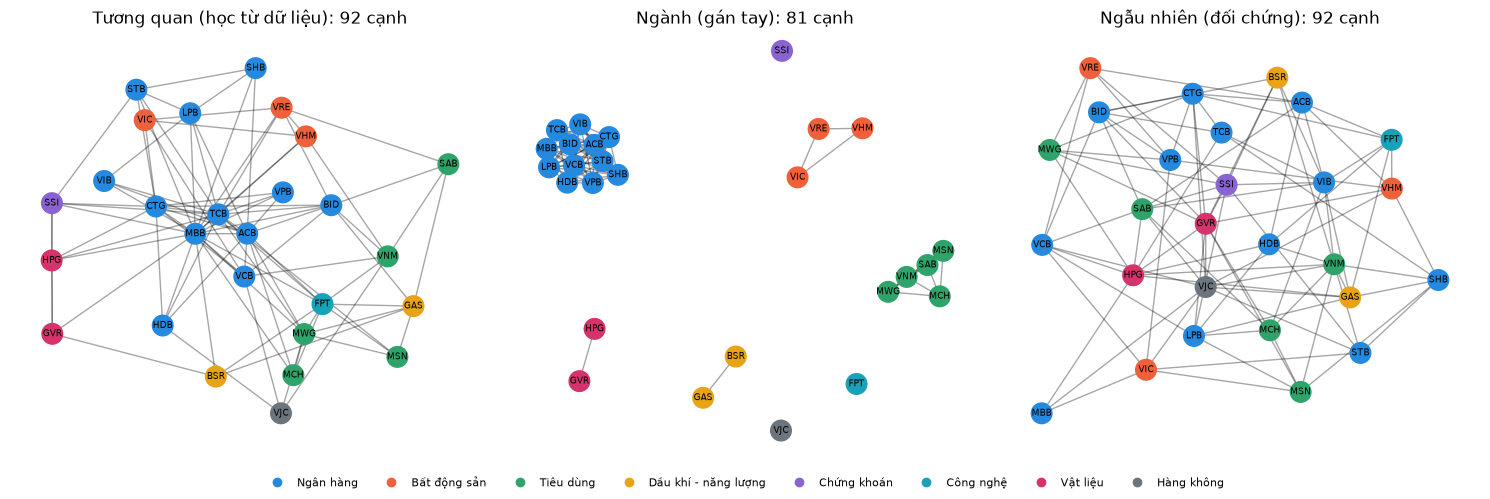

In [6]:
sec_of = {t: s for s, ts in G.SECTORS.items() for t in ts}
palette = dict(zip(G.SECTORS, ["#2589e0", "#f0603a", "#2fa46a", "#e8a317", "#8a63d2", "#17a2b8", "#d6336c", "#6c757d"]))
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, title) in zip(axes, [("corr", "Tương quan (học từ dữ liệu)"), ("sector", "Ngành (gán tay)"), ("random", "Ngẫu nhiên (đối chứng)")]):
    g = nx.from_numpy_array(A[name])
    pos = nx.spring_layout(g, seed=3, k=0.6)
    nx.draw_networkx_edges(g, pos, ax=ax, alpha=0.35)
    nx.draw_networkx_nodes(g, pos, ax=ax, node_color=[palette[sec_of[t]] for t in tickers], node_size=220)
    nx.draw_networkx_labels(g, pos, labels=dict(enumerate(tickers)), font_size=6.5, ax=ax)
    ax.set_title(f"{title}: {int(A[name].sum() / 2)} cạnh"); ax.axis("off")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=s) for s, c in palette.items()]
fig.legend(handles=handles, loc="lower center", ncol=8, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

## 5. GCN: công thức và mã

**Một lớp GCN** cập nhật biểu diễn các nút theo công thức  $H' = \mathrm{ReLU}(\hat A\,H\,W)$, với $\hat A = D^{-1/2}(A+I)D^{-1/2}$.
- $A+I$: thêm **vòng tự nối** để nút giữ lại thông tin của chính nó.
- $D$: ma trận bậc (đường chéo = số hàng xóm + 1). Nhân $D^{-1/2}$ hai phía để nút có nhiều hàng xóm không "nuốt" nhiều hơn nút ít hàng xóm.
- $HW$: biến đổi tuyến tính từng nút; nhân $\hat A$ rồi **trung bình có trọng số** biểu diễn của nút với các hàng xóm.

Hàm `norm_adj` tính $\hat A$. Ô dưới kiểm tra trên một đồ thị nhỏ 4 nút (đường thẳng 0–1–2–3) để thấy các hàng của $\hat A$ nhìn như thế nào, và kiểm tra rằng phép nhân ma trận cho cùng kết quả với tính tay cho nút 1.

In [7]:
show_source(G.norm_adj)
a_small = np.array([[0, 1, 0, 0], [1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0]], dtype=float)
a_hat = G.norm_adj(a_small)
print("A_hat của đồ thị 4 nút (đường thẳng 0-1-2-3):")
print(np.round(a_hat, 3))
h = np.arange(8, dtype=np.float32).reshape(4, 2)   # 4 nút, 2 đặc trưng
by_matrix = (a_hat @ h)[1]
# tính tay cho nút 1: hàng xóm là 0, 2 và chính nó, bậc (có vòng tự nối) lần lượt 2, 3, 3, 2
d = a_small.sum(1) + 1
by_hand = h[0] / np.sqrt(d[1] * d[0]) + h[1] / d[1] + h[2] / np.sqrt(d[1] * d[2])
print("Nút 1 sau trộn, bằng ma trận:", np.round(by_matrix, 4), "| tính tay:", np.round(by_hand, 4))
assert np.allclose(by_matrix, by_hand, atol=1e-5)

def norm_adj(a):
    a = a + np.eye(len(a))
    d = a.sum(1)
    return (a / np.sqrt(d[:, None] * d[None, :])).astype(np.float32)

A_hat của đồ thị 4 nút (đường thẳng 0-1-2-3):
[[0.5   0.408 0.    0.   ]
 [0.408 0.333 0.333 0.   ]
 [0.    0.333 0.333 0.408]
 [0.    0.    0.408 0.5  ]]
Nút 1 sau trộn, bằng ma trận: [2.     3.0749] | tính tay: [2.     3.0749]


**Lớp `GCN` trong mã** (hai lớp GCN rồi một lớp tuyến tính ra logit cho từng nút):
- `register_buffer("A", ...)` lưu $\hat A$ như hằng số của mô hình (đi theo `.to(device)` nhưng **không được học**).
- `forward`: `self.A @ self.w1(x)` = nhân $\hat A$ (27×27) với biểu diễn của các nút theo từng ngày; ReLU; Dropout; lặp lại lần hai; `out` cho **một logit mỗi nút**.
- Phép `@` hoạt động trên lô: `x` có dạng `(lô ngày, nút, đặc trưng)`, `A` là `(nút, nút)`, nên mỗi ngày trong lô được trộn bằng cùng một đồ thị.

**`NodeMLP`** cùng cỡ nhưng **không có `A`**: tương đương $\hat A = I$, mỗi nút chỉ nhìn đặc trưng của chính mình. So GCN với MLP cho biết đồ thị có đóng góp gì.

In [8]:
show_source(G.GCN)
show_source(G.NodeMLP)
gcn = G.GCN(G.norm_adj(A["corr"]), X.shape[-1])
mlp = G.NodeMLP(X.shape[-1])
xb = torch.tensor(Xn[:4])
print("Đầu vào:", tuple(xb.shape), "-> GCN:", tuple(gcn(xb).shape), "| MLP:", tuple(mlp(xb).shape), "(lô, nút)")
n_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print("Số tham số học được — GCN:", n_params(gcn), "| MLP:", n_params(mlp))

class GCN(nn.Module):
    """Hai lớp GCN dạng ma trận kề chuẩn hóa A_hat: H' = ReLU(A_hat H W), rồi lớp tuyến tính ra logit cho từng nút."""

    def __init__(self, a_hat, f_in, hid=32, drop=0.3):
        super().__init__()
        self.register_buffer("A", torch.tensor(a_hat))
        self.w1, self.w2 = nn.Linear(f_in, hid), nn.Linear(hid, hid)
        self.out, self.drop = nn.Linear(hid, 1), nn.Dropout(drop)

    def forward(self, x):  # x: (lô ngày, nút, đặc trưng)
        h = torch.relu(self.A @ self.w1(x))
        h = self.drop(h)
        h = torch.relu(self.A @ self.w2(h))
        return self.out(self.drop(h)).squeeze(-1)

class NodeMLP(nn.Module):
    """Cùng cỡ với GCN nhưng không trộn thông tin giữa các nút (A_hat = I)."""

    def __init__(self, f_in, hid=32, drop=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(f_in, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, 1))

    def forward(self, x):
  

## 6. Huấn luyện thu nhỏ và các độ đo

**Hàm `fit`:** AdamW (có weight decay), hàm mất mát `BCEWithLogitsLoss` (sigmoid gộp vào mất mát cho ổn định số), mini-batch 64 ngày. Mỗi epoch đo **AUC trên validation** và giữ lại
trọng số tốt nhất (`best_state`) rồi nạp lại ở cuối: đây là **chọn epoch bằng validation**, test không tham gia.

**Hàm `metrics`** trên tập test, có bốn độ đo:
- `accuracy` và `auc`: phân loại trên nhãn "cao hơn trung vị rổ"; đoán mò cho 0,5.
- `ic` (information coefficient): tương quan hạng Spearman giữa điểm dự đoán và lợi suất 5 phiên, tính **từng ngày** rồi lấy trung bình.
- `top5_excess`: mỗi ngày chọn 5 mã điểm cao nhất, lấy lợi suất 5 phiên trung bình của chúng trừ trung bình cả rổ. Đây là phần vượt trội **trước phí** nếu giao dịch theo mô hình.

Ô dưới huấn luyện GCN (đồ thị tương quan) và MLP **một seed, 30 epoch**; bảng chính thức ở Phần 7.

In [9]:
show_source(G.fit)
show_source(G.metrics)
rows, curves = {}, {}
for name, model in [("GCN, đồ thị tương quan", G.GCN(G.norm_adj(A["corr"]), X.shape[-1])), ("MLP (không đồ thị)", G.NodeMLP(X.shape[-1]))]:
    t0 = time.time()
    hist, best = G.fit(model, Xn[tr_i], y[tr_i], Xn[va_i], y[va_i], seed=0, epochs=30)
    curves[name] = hist
    rows[name] = G.metrics(y[te_i], G.predict(model, Xn[te_i]), fwd[te_i]) | {"val_auc tốt nhất": best, "giây": time.time() - t0}
display(pd.DataFrame(rows).T.round(4))

def fit(model, Xtr, ytr, Xva, yva, seed, epochs=80, lr=2e-3, wd=1e-3, bs=64):
    torch.manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.BCEWithLogitsLoss()
    best, best_state, hist = -1, None, []
    xt, yt = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(ytr, dtype=torch.float32)
    xv = torch.tensor(Xva, dtype=torch.float32)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(xt))
        tot = 0.0
        for i in range(0, len(xt), bs):
            b = perm[i:i + bs]
            opt.zero_grad()
            loss = lossf(model(xt[b]), yt[b])
            loss.backward()
            opt.step()
            tot += float(loss) * len(b)
        model.eval()
        with torch.no_grad():
            pv = torch.sigmoid(model(xv)).numpy()
        a = auc(yva, pv)
        hist.append(dict(epoch=ep + 1, train_loss=tot / len(xt), val_auc=a))
        if a > best:
            best, best_state = a, {k:

,accuracy,auc,ic,top5_excess,val_auc tốt nhất,giây
"GCN, đồ thị tương quan",0.5068,0.5019,0.0054,-0.0001,0.5191,10.1000
MLP (không đồ thị),0.5094,0.4978,-0.0054,-0.0010,0.5304,2.2618


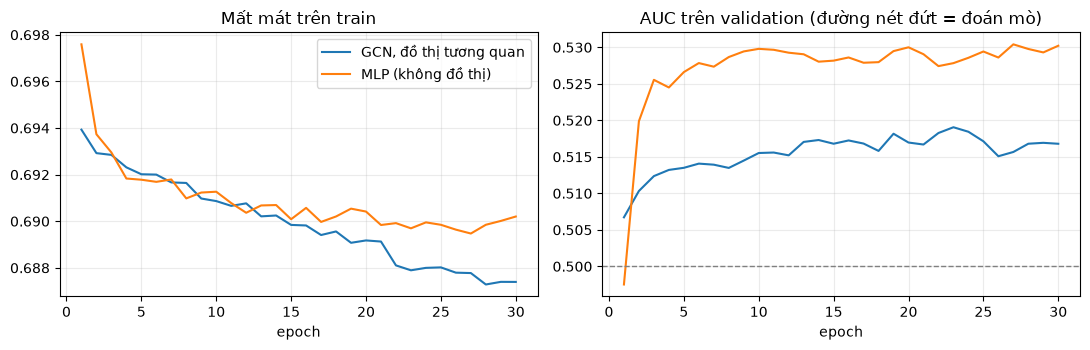

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, hist in curves.items():
    ax[0].plot([h["epoch"] for h in hist], [h["train_loss"] for h in hist], label=name)
    ax[1].plot([h["epoch"] for h in hist], [h["val_auc"] for h in hist], label=name)
ax[0].set_title("Mất mát trên train"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].axhline(0.5, color="gray", ls="--", lw=1); ax[1].set_title("AUC trên validation (đường nét đứt = đoán mò)"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

**Cách đọc:** mất mát train giảm đều nghĩa là mô hình **đang học được gì đó trên train**, nhưng AUC validation quanh 0,5 cho thấy phần học được **không tổng quát** sang năm khác.
Đây là dấu hiệu quen thuộc của dữ liệu tài chính: tín hiệu rất nhỏ so với nhiễu.

## 7. Bảng kết quả chính thức: 5 seed, 80 epoch (bài toán A)

Số liệu dưới đây sinh bởi `python -m scripts.tieuluan.complete_gnn` (khoảng 3–4 phút) và lưu ở `data/tieuluan/gnn/results.json`. Mỗi ô là **trung bình ± độ lệch chuẩn qua 5 seed**.
Mục tiêu của bảng là kiểm tra xem khác biệt giữa các mô hình có lớn hơn độ dao động giữa các seed hay không.

1602 ngày, 27 mã, 8 đặc trưng; chia train/val/test = {'train': 679, 'val': 244, 'test': 669}; số cạnh {'corr': 92, 'sector': 81, 'random': 92}


,accuracy,auc,ic,top5_excess
Logistic Regression,0.5143 ± 0.0000,0.4968 ± 0.0000,-0.0066 ± 0.0000,-0.0006 ± 0.0000
MLP (không đồ thị),0.5110 ± 0.0040,0.5021 ± 0.0034,0.0041 ± 0.0070,-0.0009 ± 0.0006
"GCN, đồ thị ngẫu nhiên",0.5150 ± 0.0047,0.5020 ± 0.0045,0.0030 ± 0.0102,0.0000 ± 0.0005
"GCN, đồ thị ngành",0.5129 ± 0.0042,0.5009 ± 0.0040,-0.0044 ± 0.0113,0.0011 ± 0.0005
"GCN, đồ thị tương quan",0.5132 ± 0.0039,0.5060 ± 0.0039,0.0112 ± 0.0081,0.0009 ± 0.0006


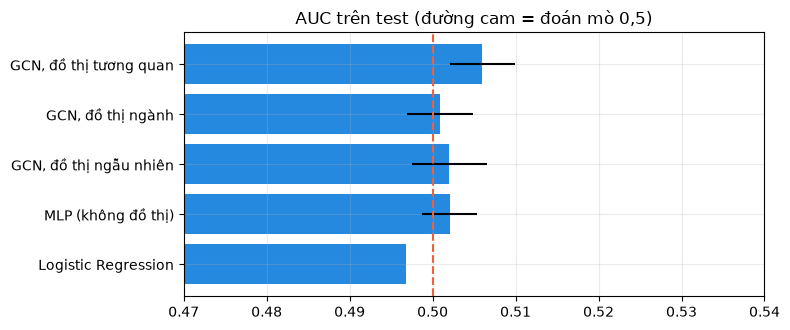

In [11]:
res = json.load(open(ROOT / "data/tieuluan/gnn/results.json", encoding="utf-8"))
info = res["info"]
print(f"{info['n_days']} ngày, {len(info['tickers'])} mã, {info['n_features']} đặc trưng; chia train/val/test = {info['split']}; số cạnh {info['edges']}")
tab = pd.DataFrame({name: {m: f"{v[m]['mean']:.4f} ± {v[m]['std']:.4f}" for m in ("accuracy", "auc", "ic", "top5_excess")} for name, v in res["results"].items()}).T
display(tab)
fig, ax = plt.subplots(figsize=(8, 3.4))
names = list(res["results"]); vals = [res["results"][n]["auc"]["mean"] for n in names]; errs = [res["results"][n]["auc"]["std"] for n in names]
ax.barh(names, vals, xerr=errs, color="#2589e0"); ax.axvline(0.5, color="#f0603a", ls="--"); ax.set_xlim(0.47, 0.54)
ax.set_title("AUC trên test (đường cam = đoán mò 0,5)"); plt.tight_layout(); plt.show()

**Kết luận thật của bài toán A:** mọi mô hình có AUC trong khoảng 0,497–0,506, **không khác đoán mò** so với độ dao động giữa các seed. GCN trên đồ thị tương quan nhỉnh nhất (AUC 0,506, IC 0,011),
nhưng mức chênh này nhỏ hơn nhiều so với độ lệch chuẩn nên **không thể nói đồ thị giúp dự báo lợi suất**. Điều này phù hợp với giả thuyết thị trường hiệu quả ở mức yếu cho khung 5 phiên.
Chênh lệch `top5_excess` cỡ 0,1% cho 5 phiên là **trước phí và thuế**, nên không có ý nghĩa giao dịch.

## 8. Bài toán B: phân loại nút bán giám sát (đồ thị thật sự phát huy)

Dự báo giá nhiễu quá lớn nên ta thử một bài toán mà **cấu trúc đồ thị có ý nghĩa rõ**: chỉ biết ngành của **9/27 mã** (1/3, chọn phân tầng theo lớp), đoán xem 18 mã còn lại có thuộc **Ngân hàng** hay không.
Đặc trưng của nút chỉ là **thống kê riêng của từng mã** (độ biến động, beta, độ lệch, độ nhọn, log khối lượng, tự tương quan bậc 1), tuyệt đối không chứa thông tin về hàng xóm.
GCN phải lấy thông tin từ hàng xóm qua $\hat A$.

**Hàm `run_sector`:** lặp 40 lần chia ngẫu nhiên tập có nhãn, huấn luyện 150 bước cho từng mô hình, đo độ chính xác trên các nút không có nhãn.
Ô dưới chạy **một lần chia** để thấy cơ chế, rồi đọc bảng 40 lần chia từ `results.json`.

In [12]:
show_source(G.run_sector)
_, tk, f, label, cm = G.sector_data()
n = len(tk)
print("Đặc trưng nút (đã chuẩn hóa):", f.shape, "| số mã Ngân hàng:", int(label.sum()), "/", n, "| tỉ lệ lớp đa số:", round(max(label.mean(), 1 - label.mean()), 3))
same = [(label[i] == label[j]) for i in range(n) for j in range(n) if A["corr"][i, j]]
print("Tỉ lệ cạnh tương quan nối hai mã CÙNG nhóm (homophily):", round(float(np.mean(same)), 3))

rng = np.random.default_rng(0)
tr_idx = np.concatenate([rng.choice(np.where(label == c)[0], size=max(2, int(round((label == c).sum() / 3))), replace=False) for c in (0, 1)])
te_idx = np.setdiff1d(np.arange(n), tr_idx)
x = torch.tensor(f, dtype=torch.float32)[None]; yt = torch.tensor(label, dtype=torch.float32)

def train_eval(model, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-2, weight_decay=1e-2)
    for _ in range(150):
        model.train(); opt.zero_grad()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(model(x)[0][tr_idx], yt[tr_idx])
        loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        pred = (torch.sigmoid(model(x)[0][te_idx]) > 0.5).float()
    return float((pred == yt[te_idx]).float().mean())

one = {"MLP (không đồ thị)": train_eval(G.NodeMLP(f.shape[1], hid=16, drop=0.2)),
       "GCN, đồ thị tương quan": train_eval(G.GCN(G.norm_adj(A["corr"]), f.shape[1], hid=16, drop=0.2)),
       "GCN, đồ thị ngẫu nhiên": train_eval(G.GCN(G.norm_adj(A["random"]), f.shape[1], hid=16, drop=0.2))}
print("Một lần chia (9 mã có nhãn, 18 mã cần đoán), độ chính xác:", {k: round(v, 3) for k, v in one.items()})

def run_sector():
    """Bài toán B (phân loại nút, bán giám sát): chỉ biết ngành của 1/3 số mã, đoán ngành (Ngân hàng hay không) cho phần còn lại.
    Đặc trưng nút chỉ là thống kê riêng của từng mã (độ biến động, beta, khối lượng...), không chứa thông tin về hàng xóm."""
    from sklearn.linear_model import LogisticRegression
    close, tickers, f, label, _ = sector_data()
    A, _ = graphs(close, close.index <= pd.Timestamp(SPLIT["train_end"]), tickers)
    n = len(tickers)
    rows = {k: [] for k in ("Logistic Regression", "MLP (không đồ thị)", "GCN, đồ thị ngẫu nhiên", "GCN, đồ thị tương quan", "GCN, đồ thị ngành (tham khảo)")}
    homophily = float(np.mean([label[i] == label[j] for i in range(n) for j in range(n) if A["corr"][i, j]]))
    for rep in range(40):
        rng = np.random.default_rng(rep)
        tr_idx = np.concatenate([rng.choice(np.where(label == c)[0], size=max(2, int(round((label == c).sum() / 3))), replace=False) for c in (0, 1)])
        te_idx = np.setdiff1d(n

Đặc trưng nút (đã chuẩn hóa): (27, 6) | số mã Ngân hàng: 12 / 27 | tỉ lệ lớp đa số: 0.556
Tỉ lệ cạnh tương quan nối hai mã CÙNG nhóm (homophily): 0.663


Một lần chia (9 mã có nhãn, 18 mã cần đoán), độ chính xác: {'MLP (không đồ thị)': 0.611, 'GCN, đồ thị tương quan': 0.556, 'GCN, đồ thị ngẫu nhiên': 0.389}


Thông tin: {'nodes': 27, 'labelled': 9, 'repeats': 40, 'majority_rate': 0.5555555555555556, 'corr_edge_homophily': 0.6630434782608695}


,trung bình,độ lệch chuẩn
Logistic Regression,0.668,0.065
MLP (không đồ thị),0.639,0.085
"GCN, đồ thị ngẫu nhiên",0.531,0.102
"GCN, đồ thị tương quan",0.731,0.095
"GCN, đồ thị ngành (tham khảo)",0.922,0.070


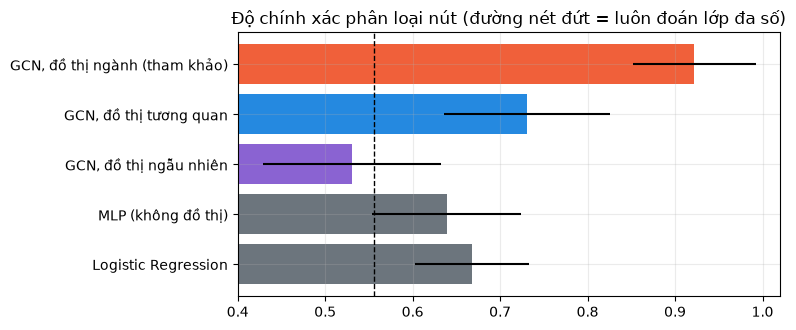

In [13]:
sec = res["sector_task"]
print("Thông tin:", {k: v for k, v in sec["_info"].items() if k != "features"})
tb = pd.DataFrame({k: {"trung bình": v["mean"], "độ lệch chuẩn": v["std"]} for k, v in sec.items() if not k.startswith("_")}).T
display(tb.round(3))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(tb.index, tb["trung bình"], xerr=tb["độ lệch chuẩn"], color=["#6c757d", "#6c757d", "#8a63d2", "#2589e0", "#f0603a"])
ax.axvline(sec["_info"]["majority_rate"], color="k", ls="--", lw=1); ax.set_xlim(0.4, 1.02)
ax.set_title("Độ chính xác phân loại nút (đường nét đứt = luôn đoán lớp đa số)"); plt.tight_layout(); plt.show()

**Kết luận thật của bài toán B:**
- GCN trên đồ thị tương quan đạt **0,731**, cao hơn MLP (0,639) và Logistic Regression (0,668) và vượt mức đoán lớp đa số (0,556): thông tin từ hàng xóm **giúp thật**.
- GCN trên đồ thị **ngẫu nhiên** chỉ **0,531**, thấp hơn cả MLP: đồ thị sai làm hại. Vậy lợi ích đến từ **cấu trúc đúng**, không phải từ việc "có thêm phép trộn".
- GCN trên đồ thị ngành đạt 0,922 nhưng đây là **rò rỉ nhãn**: đồ thị ngành được dựng đúng từ nhãn ngành, nên nó chỉ là mốc tham khảo (chặn trên), không dùng để kết luận.
- Lần chia đơn ở ô trên (GCN 0,556, MLP 0,611) **chưa nói lên điều gì**: chỉ 9 mã có nhãn và 18 mã để đoán nên mỗi lần chia rất nhiễu; chính vì vậy cần trung bình 40 lần chia.
- Tỉ lệ homophily của đồ thị tương quan là 0,663: khoảng hai phần ba cạnh nối hai mã cùng nhóm. GCN chỉ hơn được khi đồ thị đủ đồng nhất như vậy.

## 9. Giới hạn: over-smoothing

Mỗi lớp GCN thêm một lần nhân $\hat A$. Nhân nhiều lần, biểu diễn của các nút bị **trộn đến khi gần giống nhau** và mất khả năng phân biệt. Ta thấy hiện tượng này
chỉ bằng đại số tuyến tính: lấy đặc trưng nút `f` của bài toán B và tính $\hat A^k f$ với $k = 0..12$, đo **độ lệch chuẩn giữa các nút** (trung bình theo đặc trưng).
Nếu số này tiến về 0 thì các nút đã không còn phân biệt được. Đây là lý do mô hình dùng **chỉ 2 lớp GCN**.

corr   : k=0 1.000 | k=2 0.256 | k=6 0.055 | k=12 0.015
random : k=0 1.000 | k=2 0.139 | k=6 0.013 | k=12 0.003
sector : k=0 1.000 | k=2 0.634 | k=6 0.634 | k=12 0.634


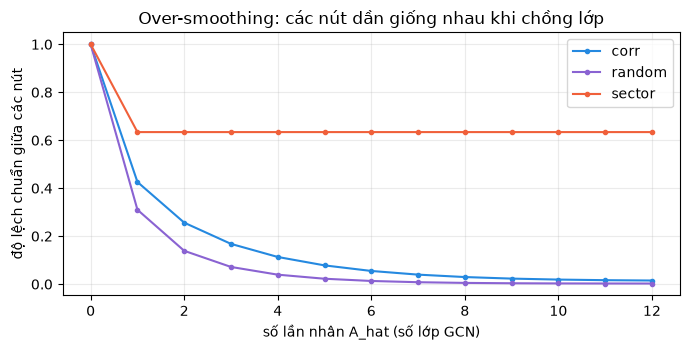

In [14]:
def spread_by_depth(adj, f, depth=12):
    ah = G.norm_adj(adj); h = f.astype(np.float64).copy(); out = []
    for k in range(depth + 1):
        out.append(float(h.std(axis=0).mean()))
        h = ah @ h
    return out

fig, ax = plt.subplots(figsize=(7, 3.6))
for name, col in [("corr", "#2589e0"), ("random", "#8a63d2"), ("sector", "#f0603a")]:
    s = spread_by_depth(A[name], f)
    ax.plot(range(len(s)), s, marker="o", ms=3, label=name, color=col)
    print(f"{name:<7}: k=0 {s[0]:.3f} | k=2 {s[2]:.3f} | k=6 {s[6]:.3f} | k=12 {s[12]:.3f}")
ax.set_xlabel("số lần nhân A_hat (số lớp GCN)"); ax.set_ylabel("độ lệch chuẩn giữa các nút")
ax.set_title("Over-smoothing: các nút dần giống nhau khi chồng lớp"); ax.legend(); plt.tight_layout(); plt.show()

**Cách đọc:** với đồ thị tương quan và ngẫu nhiên (liên thông), độ phân tán giữa các nút giảm gần về 0 khi chồng lớp: sau 12 lần trộn các nút gần như giống hệt nhau. Đồ thị ngẫu nhiên tan nhanh nhất vì
các cạnh của nó nối khắp nơi. Đồ thị ngành thì **không tan về 0** (dừng ở khoảng 0,63) vì nó gồm các cụm tách rời: trong mỗi ngành các mã trở nên giống nhau, nhưng các ngành khác nhau không trộn với nhau.
Với 2 lớp, độ phân tán còn 0,26 (tương quan), vẫn đủ để mô hình dùng; vì vậy GCN trong chương này chỉ dùng 2 lớp.

## 10. Tổng kết, hạn chế và câu hỏi trình bày

**Tổng kết**
1. Nút = cổ phiếu, cạnh = tương quan hoặc cùng ngành, GCN trộn đặc trưng theo $\hat A = D^{-1/2}(A+I)D^{-1/2}$.
2. Bài toán A (dự báo lợi suất 5 phiên): **đồ thị không giúp**, mọi mô hình quanh mức đoán mò (AUC ≈ 0,50).
3. Bài toán B (phân loại nút bán giám sát): GCN trên đồ thị tương quan **vượt** MLP và Logistic Regression; đồ thị ngẫu nhiên **làm hại**; đồ thị ngành là rò rỉ nhãn.
4. Chồng nhiều lớp thì over-smoothing (nút gần như giống nhau sau 12 lớp ở đồ thị liên thông): giữ GCN nông.

**Hạn chế:** chỉ 27 mã; phân ngành gán thủ công; một lần chia thời gian cho bài toán A; bài toán B có 27 nút nên độ lệch chuẩn qua 40 lần chia còn lớn; đồ thị tĩnh (tương quan tính trên train, không cập nhật).

**Câu hỏi trình bày**
- Tại sao nhãn dùng trung vị của rổ thay vì "tăng/giảm" tuyệt đối?
- Vòng tự nối `+I` và chuẩn hóa `D^{-1/2}` làm gì? Điều gì xảy ra nếu bỏ chúng?
- Vì sao đồ thị tương quan chỉ tính trên giai đoạn train? Nếu tính trên toàn bộ dữ liệu thì rò rỉ ở đâu?
- Vì sao GCN đồ thị ngẫu nhiên tệ hơn MLP ở bài toán B, và điều đó nói gì về vai trò của đồ thị?
- Vì sao kết quả GCN đồ thị ngành (0,922) không dùng để kết luận?